In [1]:
# ============================================================
# WEEK 10: ROBUSTNESS ANALYSIS
# Deepfake Detection using ResNet50
# ============================================================

import os
import random
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

from torchvision import transforms, models
from PIL import Image, ImageFilter, ImageEnhance

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix
)

# ------------------------------------------------------------
# PROJECT PATHS
# ------------------------------------------------------------

ROOT = Path.cwd().parent

RESULTS_DIR = ROOT / "results"
MODELS_DIR = ROOT / "models"

RESULTS_DIR.mkdir(exist_ok=True)
MODELS_DIR.mkdir(exist_ok=True)

CHECKPOINT_PATH = MODELS_DIR / "week4_resnet50.pth"
METADATA_PATH = RESULTS_DIR / "final_face_metadata.csv"

# ------------------------------------------------------------
# DEVICE
# ------------------------------------------------------------

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Week 10: Robustness Analysis")
print("Project Root:", ROOT)
print("Device:", device)
print("CUDA Available:", torch.cuda.is_available())
print("Checkpoint Exists:", CHECKPOINT_PATH.exists())
print("Metadata Exists:", METADATA_PATH.exists())

Week 10: Robustness Analysis
Project Root: c:\Users\HIMANSHU\Desktop\minor project 1\Minor-Project
Device: cuda
CUDA Available: True
Checkpoint Exists: True
Metadata Exists: True


In [2]:
# ============================================================
# CELL 2: LOAD TEST DATASET
# ============================================================

metadata_df = pd.read_csv(METADATA_PATH)

# Keep only valid test images
test_df = metadata_df[
    (metadata_df["split"] == "test") &
    (metadata_df["file_exists"] == True)
].copy()

# Reset index
test_df.reset_index(drop=True, inplace=True)

print("Total Test Images:", len(test_df))
print("Unique Test Videos:", test_df["video_id"].nunique())

print("\nClass Distribution:")
print(test_df["class_name"].value_counts())

print("\nSample Records:")
print(test_df[["face_path", "label", "class_name"]].head())

Total Test Images: 12321
Unique Test Videos: 1233

Class Distribution:
class_name
deepfake    10610
real         1711
Name: count, dtype: int64

Sample Records:
                                           face_path  label class_name
0  results\processed_faces\real\id0_0001_face_00.jpg      0       real
1  results\processed_faces\real\id0_0001_face_01.jpg      0       real
2  results\processed_faces\real\id0_0001_face_02.jpg      0       real
3  results\processed_faces\real\id0_0001_face_03.jpg      0       real
4  results\processed_faces\real\id0_0001_face_04.jpg      0       real


C:\Users\HIMANSHU\AppData\Local\Temp\ipykernel_17092\1533942564.py:14: Pandas4Warning: The inplace keyword in DataFrame.reset_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  test_df.reset_index(drop=True, inplace=True)


In [3]:
# ============================================================
# CELL 3: DEFINE TEST DATASET
# ============================================================

class RobustnessDataset(Dataset):

    def __init__(self, dataframe, root, transform=None):
        self.dataframe = dataframe.reset_index(drop=True)
        self.root = Path(root)
        self.transform = transform

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, index):

        row = self.dataframe.iloc[index]

        image_path = Path(row["face_path"])

        if not image_path.is_absolute():
            image_path = self.root / image_path

        image = Image.open(image_path).convert("RGB")
        label = int(row["label"])

        if self.transform:
            image = self.transform(image)

        return image, label


test_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

test_dataset = RobustnessDataset(
    dataframe=test_df,
    root=ROOT,
    transform=test_transform
)

BATCH_SIZE = 16

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=True
)

print("Test Dataset Size:", len(test_dataset))
print("Test Batches:", len(test_loader))

images, labels = next(iter(test_loader))

print("Image Batch Shape:", images.shape)
print("Label Batch Shape:", labels.shape)
print("First Batch Labels:", labels[:10].tolist())

Test Dataset Size: 12321
Test Batches: 771
Image Batch Shape: torch.Size([16, 3, 224, 224])
Label Batch Shape: torch.Size([16])
First Batch Labels: [0, 0, 0, 0, 0, 0, 0, 0, 0, 0]


In [5]:
# ============================================================
# CELL 4: LOAD TRAINED RESNET50 MODEL
# ============================================================

model = models.resnet50(weights=None)

model.fc = nn.Linear(
    model.fc.in_features,
    1
)

checkpoint = torch.load(
    CHECKPOINT_PATH,
    map_location=device,
    weights_only=False
)

# Handle different checkpoint formats
if isinstance(checkpoint, dict):
    if "state_dict" in checkpoint:
        state_dict = checkpoint["state_dict"]
    elif "model_state_dict" in checkpoint:
        state_dict = checkpoint["model_state_dict"]
    else:
        state_dict = checkpoint
else:
    state_dict = checkpoint

# Remove DataParallel prefix if present
state_dict = {
    key.replace("module.", "", 1): value
    for key, value in state_dict.items()
}

model.load_state_dict(state_dict)

model = model.to(device)
model.eval()

print("ResNet50 loaded successfully!")
print("Device:", device)
print("Model Parameters:", sum(p.numel() for p in model.parameters()))
print("Model Mode:", "Evaluation")

ResNet50 loaded successfully!
Device: cuda
Model Parameters: 23510081
Model Mode: Evaluation


In [6]:
# ============================================================
# CELL 5: BASELINE PREDICTIONS
# ============================================================

all_labels = []
all_probabilities = []

model.eval()

with torch.no_grad():

    for batch_idx, (images, labels) in enumerate(test_loader):

        images = images.to(device)

        outputs = model(images).squeeze(1)

        probabilities = torch.sigmoid(outputs)

        all_labels.extend(labels.numpy())
        all_probabilities.extend(probabilities.cpu().numpy())

        if (batch_idx + 1) % 100 == 0:
            print(f"Processed: {batch_idx + 1}/{len(test_loader)}")

# Convert to NumPy arrays
y_true = np.array(all_labels)
baseline_probabilities = np.array(all_probabilities)

# Apply Week 8 optimized threshold
BEST_THRESHOLD = 0.14

baseline_predictions = (
    baseline_probabilities >= BEST_THRESHOLD
).astype(int)

print("\nBaseline Predictions Completed!")
print("Total Images:", len(y_true))
print("Threshold:", BEST_THRESHOLD)
print("Probability Shape:", baseline_probabilities.shape)

Processed: 100/771
Processed: 200/771
Processed: 300/771
Processed: 400/771
Processed: 500/771
Processed: 600/771
Processed: 700/771

Baseline Predictions Completed!
Total Images: 12321
Threshold: 0.14
Probability Shape: (12321,)


In [7]:
# ============================================================
# CELL 6: BASELINE PERFORMANCE EVALUATION
# ============================================================

baseline_metrics = {
    "Condition": "Original",
    "Accuracy": accuracy_score(y_true, baseline_predictions),
    "Precision": precision_score(
        y_true, baseline_predictions, zero_division=0
    ),
    "Recall": recall_score(
        y_true, baseline_predictions, zero_division=0
    ),
    "F1-Score": f1_score(
        y_true, baseline_predictions, zero_division=0
    ),
    "ROC-AUC": roc_auc_score(
        y_true, baseline_probabilities
    )
}

baseline_df = pd.DataFrame([baseline_metrics])

print("BASELINE PERFORMANCE")
print(baseline_df.to_string(index=False))

print("\nConfusion Matrix:")
print(confusion_matrix(y_true, baseline_predictions))

# Save baseline results
baseline_df.to_csv(
    RESULTS_DIR / "week10_baseline_metrics.csv",
    index=False
)

print("\nBaseline metrics saved successfully!")

BASELINE PERFORMANCE
Condition  Accuracy  Precision   Recall  F1-Score  ROC-AUC
 Original  0.906826   0.913766 0.984731  0.947922 0.833104

Confusion Matrix:
[[  725   986]
 [  162 10448]]

Baseline metrics saved successfully!


In [8]:
# ============================================================
# CELL 7: BRIGHTNESS ROBUSTNESS TEST
# ============================================================

brightness_levels = [0.5, 0.75, 1.25, 1.5]

brightness_results = []

for factor in brightness_levels:

    print(f"\nTesting Brightness Factor: {factor}")

    brightness_transform = transforms.Compose([
        transforms.Resize((224, 224)),
        transforms.Lambda(
            lambda img: ImageEnhance.Brightness(img).enhance(factor)
        ),
        transforms.ToTensor(),
        transforms.Normalize(
            mean=[0.485, 0.456, 0.406],
            std=[0.229, 0.224, 0.225]
        )
    ])

    brightness_dataset = RobustnessDataset(
        dataframe=test_df,
        root=ROOT,
        transform=brightness_transform
    )

    brightness_loader = DataLoader(
        brightness_dataset,
        batch_size=BATCH_SIZE,
        shuffle=False,
        num_workers=0,
        pin_memory=True
    )

    probabilities = []

    with torch.no_grad():

        for batch_idx, (images, labels) in enumerate(brightness_loader):

            images = images.to(device)

            outputs = model(images).squeeze(1)

            probs = torch.sigmoid(outputs)

            probabilities.extend(probs.cpu().numpy())

    probabilities = np.array(probabilities)

    predictions = (
        probabilities >= BEST_THRESHOLD
    ).astype(int)

    metrics = {
        "Condition": f"Brightness_{factor}",
        "Accuracy": accuracy_score(y_true, predictions),
        "Precision": precision_score(
            y_true, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_true, predictions, zero_division=0
        ),
        "F1-Score": f1_score(
            y_true, predictions, zero_division=0
        ),
        "ROC-AUC": roc_auc_score(y_true, probabilities)
    }

    brightness_results.append(metrics)

    print("Accuracy:", round(metrics["Accuracy"], 4))
    print("F1-Score:", round(metrics["F1-Score"], 4))

brightness_df = pd.DataFrame(brightness_results)

brightness_df.to_csv(
    RESULTS_DIR / "week10_brightness_results.csv",
    index=False
)

print("\nBRIGHTNESS ROBUSTNESS RESULTS")
print(brightness_df.to_string(index=False))
print("\nBrightness results saved successfully!")


Testing Brightness Factor: 0.5
Accuracy: 0.8984
F1-Score: 0.9439

Testing Brightness Factor: 0.75
Accuracy: 0.9071
F1-Score: 0.9482

Testing Brightness Factor: 1.25
Accuracy: 0.8986
F1-Score: 0.9431

Testing Brightness Factor: 1.5
Accuracy: 0.8878
F1-Score: 0.9368

BRIGHTNESS ROBUSTNESS RESULTS
      Condition  Accuracy  Precision   Recall  F1-Score  ROC-AUC
 Brightness_0.5  0.898385   0.899437 0.993025  0.943917 0.815068
Brightness_0.75  0.907069   0.911558 0.987936  0.948211 0.828258
Brightness_1.25  0.898628   0.912270 0.976155  0.943132 0.827112
 Brightness_1.5  0.887753   0.909397 0.965881  0.936789 0.812247

Brightness results saved successfully!


In [9]:
# ============================================================
# CELL 8: BLUR ROBUSTNESS TEST
# ============================================================

blur_levels = [1, 2, 3, 5]

blur_results = []

for radius in blur_levels:

    print(f"\nTesting Blur Radius: {radius}")

    blur_transform = transforms.Compose([
        transforms.Resize((224, 224)),
        transforms.Lambda(
            lambda img: img.filter(
                ImageFilter.GaussianBlur(radius=radius)
            )
        ),
        transforms.ToTensor(),
        transforms.Normalize(
            mean=[0.485, 0.456, 0.406],
            std=[0.229, 0.224, 0.225]
        )
    ])

    blur_dataset = RobustnessDataset(
        dataframe=test_df,
        root=ROOT,
        transform=blur_transform
    )

    blur_loader = DataLoader(
        blur_dataset,
        batch_size=BATCH_SIZE,
        shuffle=False,
        num_workers=0,
        pin_memory=True
    )

    probabilities = []

    with torch.no_grad():

        for batch_idx, (images, labels) in enumerate(blur_loader):

            images = images.to(device)

            outputs = model(images).squeeze(1)

            probs = torch.sigmoid(outputs)

            probabilities.extend(probs.cpu().numpy())

    probabilities = np.array(probabilities)

    predictions = (
        probabilities >= BEST_THRESHOLD
    ).astype(int)

    metrics = {
        "Condition": f"Blur_{radius}",
        "Accuracy": accuracy_score(y_true, predictions),
        "Precision": precision_score(
            y_true, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_true, predictions, zero_division=0
        ),
        "F1-Score": f1_score(
            y_true, predictions, zero_division=0
        ),
        "ROC-AUC": roc_auc_score(y_true, probabilities)
    }

    blur_results.append(metrics)

    print("Accuracy:", round(metrics["Accuracy"], 4))
    print("F1-Score:", round(metrics["F1-Score"], 4))

blur_df = pd.DataFrame(blur_results)

blur_df.to_csv(
    RESULTS_DIR / "week10_blur_results.csv",
    index=False
)

print("\nBLUR ROBUSTNESS RESULTS")
print(blur_df.to_string(index=False))

print("\nBlur results saved successfully!")


Testing Blur Radius: 1
Accuracy: 0.9052
F1-Score: 0.947

Testing Blur Radius: 2
Accuracy: 0.8874
F1-Score: 0.9378

Testing Blur Radius: 3
Accuracy: 0.8717
F1-Score: 0.9298

Testing Blur Radius: 5
Accuracy: 0.8598
F1-Score: 0.9239

BLUR ROBUSTNESS RESULTS
Condition  Accuracy  Precision   Recall  F1-Score  ROC-AUC
   Blur_1  0.905202   0.912386 0.984449  0.947049 0.830290
   Blur_2  0.887428   0.894314 0.985768  0.937817 0.786916
   Blur_3  0.871682   0.879147 0.986616  0.929786 0.699950
   Blur_5  0.859752   0.867328 0.988313  0.923877 0.623499

Blur results saved successfully!


In [10]:
# ============================================================
# CELL 9: GAUSSIAN NOISE ROBUSTNESS TEST
# ============================================================

noise_levels = [0.01, 0.03, 0.05, 0.10]

noise_results = []

# Reproducibility
torch.manual_seed(42)
np.random.seed(42)

for noise_level in noise_levels:

    print(f"\nTesting Noise Level: {noise_level}")

    noise_transform = transforms.Compose([
        transforms.Resize((224, 224)),
        transforms.ToTensor(),
        transforms.Normalize(
            mean=[0.485, 0.456, 0.406],
            std=[0.229, 0.224, 0.225]
        )
    ])

    noise_dataset = RobustnessDataset(
        dataframe=test_df,
        root=ROOT,
        transform=noise_transform
    )

    noise_loader = DataLoader(
        noise_dataset,
        batch_size=BATCH_SIZE,
        shuffle=False,
        num_workers=0
    )

    probabilities = []

    with torch.no_grad():

        for batch_idx, (images, labels) in enumerate(noise_loader):

            images = images.to(device)

            # Add Gaussian noise in normalized image space
            noise = torch.randn_like(images) * noise_level
            noisy_images = images + noise

            outputs = model(noisy_images).squeeze(1)

            probs = torch.sigmoid(outputs)

            probabilities.extend(probs.cpu().numpy())

    probabilities = np.array(probabilities)

    predictions = (
        probabilities >= BEST_THRESHOLD
    ).astype(int)

    metrics = {
        "Condition": f"Noise_{noise_level}",
        "Accuracy": accuracy_score(y_true, predictions),
        "Precision": precision_score(
            y_true, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_true, predictions, zero_division=0
        ),
        "F1-Score": f1_score(
            y_true, predictions, zero_division=0
        ),
        "ROC-AUC": roc_auc_score(y_true, probabilities)
    }

    noise_results.append(metrics)

    print("Accuracy:", round(metrics["Accuracy"], 4))
    print("F1-Score:", round(metrics["F1-Score"], 4))

noise_df = pd.DataFrame(noise_results)

noise_df.to_csv(
    RESULTS_DIR / "week10_noise_results.csv",
    index=False
)

print("\nNOISE ROBUSTNESS RESULTS")
print(noise_df.to_string(index=False))

print("\nNoise results saved successfully!")


Testing Noise Level: 0.01
Accuracy: 0.907
F1-Score: 0.948

Testing Noise Level: 0.03
Accuracy: 0.9024
F1-Score: 0.9455

Testing Noise Level: 0.05
Accuracy: 0.8967
F1-Score: 0.9427

Testing Noise Level: 0.1
Accuracy: 0.8891
F1-Score: 0.9394

NOISE ROBUSTNESS RESULTS
 Condition  Accuracy  Precision   Recall  F1-Score  ROC-AUC
Noise_0.01  0.906988   0.913347 0.985485  0.948046 0.830746
Noise_0.03  0.902362   0.910106 0.983789  0.945514 0.819439
Noise_0.05  0.896680   0.902839 0.986145  0.942655 0.810921
 Noise_0.1  0.889051   0.886834 0.998586  0.939398 0.768067

Noise results saved successfully!


In [11]:
# ============================================================
# CELL 10: JPEG COMPRESSION ROBUSTNESS TEST
# ============================================================

compression_levels = [90, 70, 50, 30]

compression_results = []

for quality in compression_levels:

    print(f"\nTesting JPEG Quality: {quality}")

    compression_transform = transforms.Compose([
        transforms.Resize((224, 224)),
        transforms.Lambda(
            lambda img: (
                lambda buffer: Image.open(buffer).convert("RGB")
            )(__import__("io").BytesIO(
                (lambda b: (img.save(b, format="JPEG", quality=quality), b)[1]
                )(__import__("io").BytesIO()).getvalue()
            ))
        ),
        transforms.ToTensor(),
        transforms.Normalize(
            mean=[0.485, 0.456, 0.406],
            std=[0.229, 0.224, 0.225]
        )
    ])

    compression_dataset = RobustnessDataset(
        dataframe=test_df,
        root=ROOT,
        transform=compression_transform
    )

    compression_loader = DataLoader(
        compression_dataset,
        batch_size=BATCH_SIZE,
        shuffle=False,
        num_workers=0
    )

    probabilities = []

    with torch.no_grad():

        for images, labels in compression_loader:

            images = images.to(device)

            outputs = model(images).squeeze(1)

            probs = torch.sigmoid(outputs)

            probabilities.extend(probs.cpu().numpy())

    probabilities = np.array(probabilities)

    predictions = (
        probabilities >= BEST_THRESHOLD
    ).astype(int)

    metrics = {
        "Condition": f"JPEG_Quality_{quality}",
        "Accuracy": accuracy_score(y_true, predictions),
        "Precision": precision_score(
            y_true, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_true, predictions, zero_division=0
        ),
        "F1-Score": f1_score(
            y_true, predictions, zero_division=0
        ),
        "ROC-AUC": roc_auc_score(y_true, probabilities)
    }

    compression_results.append(metrics)

    print("Accuracy:", round(metrics["Accuracy"], 4))
    print("F1-Score:", round(metrics["F1-Score"], 4))

compression_df = pd.DataFrame(compression_results)

compression_df.to_csv(
    RESULTS_DIR / "week10_compression_results.csv",
    index=False
)

print("\nCOMPRESSION ROBUSTNESS RESULTS")
print(compression_df.to_string(index=False))

print("\nCompression results saved successfully!")


Testing JPEG Quality: 90
Accuracy: 0.9075
F1-Score: 0.9484

Testing JPEG Quality: 70
Accuracy: 0.9065
F1-Score: 0.9478

Testing JPEG Quality: 50
Accuracy: 0.905
F1-Score: 0.9469

Testing JPEG Quality: 30
Accuracy: 0.8985
F1-Score: 0.9433

COMPRESSION ROBUSTNESS RESULTS
      Condition  Accuracy  Precision   Recall  F1-Score  ROC-AUC
JPEG_Quality_90  0.907475   0.913032 0.986522  0.948356 0.829735
JPEG_Quality_70  0.906501   0.913013 0.985297  0.947779 0.827188
JPEG_Quality_50  0.904959   0.912075 0.984543  0.946925 0.823806
JPEG_Quality_30  0.898466   0.909011 0.980207  0.943268 0.809969

Compression results saved successfully!


In [12]:
# ============================================================
# CELL 11: COMBINE ALL ROBUSTNESS RESULTS
# ============================================================

all_robustness_results = pd.concat(
    [
        baseline_df,
        brightness_df,
        blur_df,
        noise_df,
        compression_df
    ],
    ignore_index=True
)

# Save combined results
all_robustness_results.to_csv(
    RESULTS_DIR / "week10_all_robustness_results.csv",
    index=False
)

print("COMPLETE ROBUSTNESS ANALYSIS")
print(all_robustness_results.to_string(index=False))

print("\nTotal Conditions Tested:", len(all_robustness_results))
print("Results saved successfully!")

COMPLETE ROBUSTNESS ANALYSIS
      Condition  Accuracy  Precision   Recall  F1-Score  ROC-AUC
       Original  0.906826   0.913766 0.984731  0.947922 0.833104
 Brightness_0.5  0.898385   0.899437 0.993025  0.943917 0.815068
Brightness_0.75  0.907069   0.911558 0.987936  0.948211 0.828258
Brightness_1.25  0.898628   0.912270 0.976155  0.943132 0.827112
 Brightness_1.5  0.887753   0.909397 0.965881  0.936789 0.812247
         Blur_1  0.905202   0.912386 0.984449  0.947049 0.830290
         Blur_2  0.887428   0.894314 0.985768  0.937817 0.786916
         Blur_3  0.871682   0.879147 0.986616  0.929786 0.699950
         Blur_5  0.859752   0.867328 0.988313  0.923877 0.623499
     Noise_0.01  0.906988   0.913347 0.985485  0.948046 0.830746
     Noise_0.03  0.902362   0.910106 0.983789  0.945514 0.819439
     Noise_0.05  0.896680   0.902839 0.986145  0.942655 0.810921
      Noise_0.1  0.889051   0.886834 0.998586  0.939398 0.768067
JPEG_Quality_90  0.907475   0.913032 0.986522  0.948356 0.829

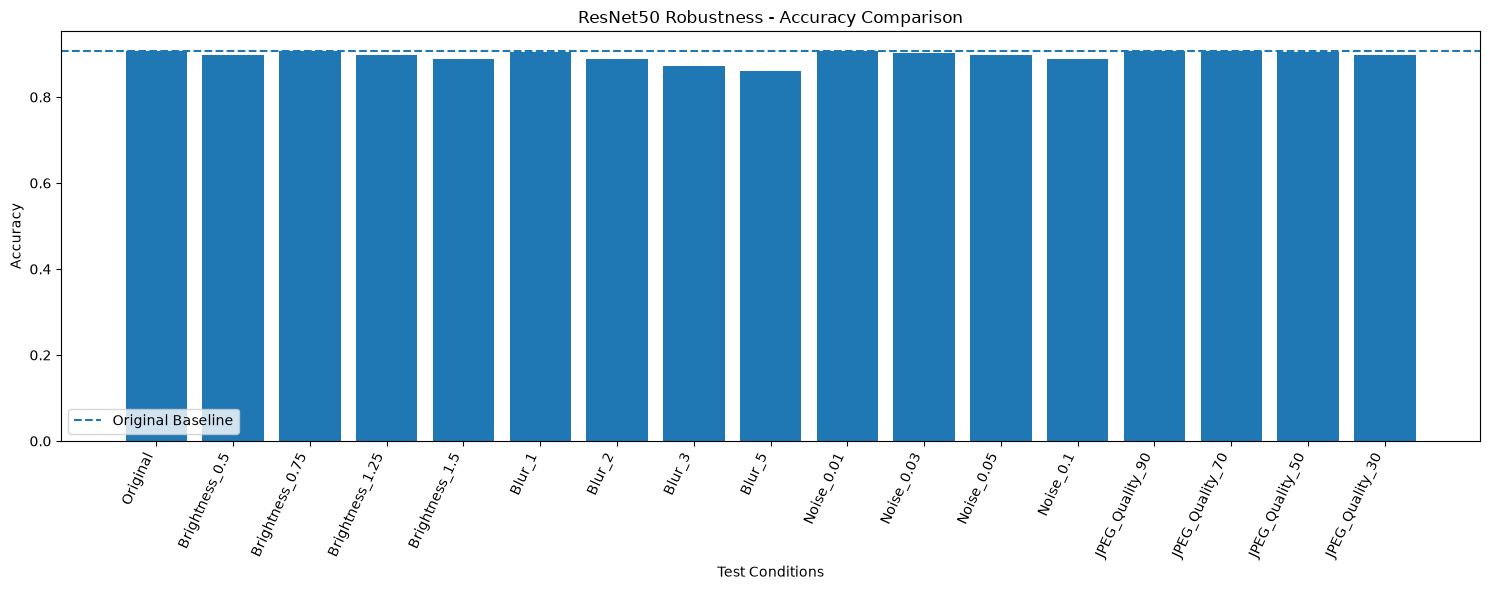

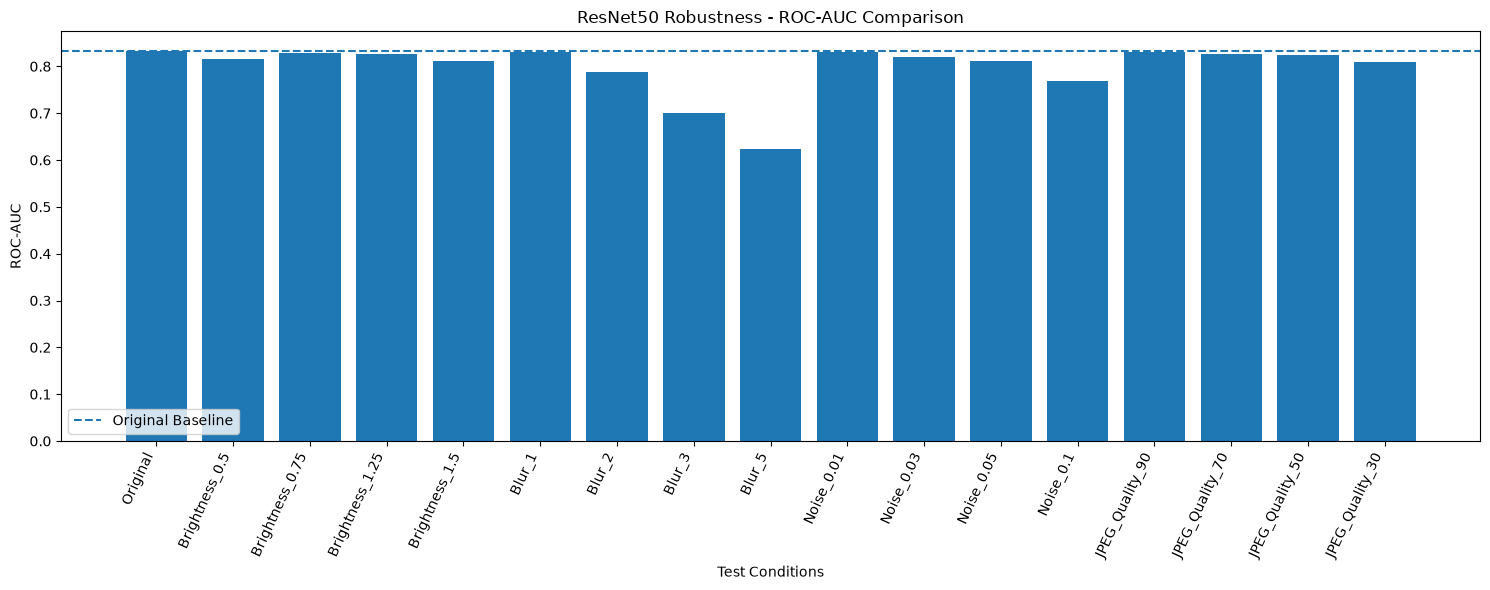

Both robustness graphs saved successfully!


In [13]:
# ============================================================
# CELL 12: FINAL ROBUSTNESS VISUALIZATION
# ============================================================

plot_df = all_robustness_results.copy()

# Accuracy comparison
plt.figure(figsize=(15, 6))

plt.bar(
    plot_df["Condition"],
    plot_df["Accuracy"]
)

plt.axhline(
    y=baseline_df["Accuracy"].iloc[0],
    linestyle="--",
    label="Original Baseline"
)

plt.title("ResNet50 Robustness - Accuracy Comparison")
plt.xlabel("Test Conditions")
plt.ylabel("Accuracy")
plt.xticks(rotation=65, ha="right")
plt.legend()
plt.tight_layout()

plt.savefig(
    RESULTS_DIR / "week10_robustness_accuracy.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ROC-AUC comparison
plt.figure(figsize=(15, 6))

plt.bar(
    plot_df["Condition"],
    plot_df["ROC-AUC"]
)

plt.axhline(
    y=baseline_df["ROC-AUC"].iloc[0],
    linestyle="--",
    label="Original Baseline"
)

plt.title("ResNet50 Robustness - ROC-AUC Comparison")
plt.xlabel("Test Conditions")
plt.ylabel("ROC-AUC")
plt.xticks(rotation=65, ha="right")
plt.legend()
plt.tight_layout()

plt.savefig(
    RESULTS_DIR / "week10_robustness_roc_auc.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Both robustness graphs saved successfully!")